In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 🔧 CHANGE #1: removed `warnings.filterwarnings('ignore')`.
# Hiding warnings is how silent bugs (like the one in the tuning step) go unnoticed.

## EDA and data inspection

In [14]:
df = pd.read_csv('adult_census_income.csv')
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [16]:
df.shape

(48842, 15)

In [17]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [18]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(52)

In [20]:
df.skew(numeric_only=True)

age                0.557580
fnlwgt             1.438892
education-num     -0.316525
capital-gain      11.894659
capital-loss       4.569809
hours-per-week     0.238750
dtype: float64

## Data cleaning

In [21]:
df.drop_duplicates(inplace=True)
df.shape

(48790, 15)

In [22]:
#This dataset stores missing values as the string '?'.
missing_q = (df == '?').sum()
print('Hidden missing values (as "?") per column:')
print(missing_q[missing_q > 0])

#removing '?' from the dataframe
df = df.replace('?', 'Unknown')
print('\nRemaining "?" values:', (df == '?').sum().sum())

Hidden missing values (as "?") per column:
workclass         2795
occupation        2805
native-country     856
dtype: int64

Remaining "?" values: 0


## Converting Target column

In [23]:
df['income'] = df['income'].map({
    '<=50K': 0,
    '>50K' : 1
})
df['income'].head()

0    0
1    0
2    0
3    0
4    0
Name: income, dtype: int64

## Column Inspection 

In [24]:
cat_col = df.select_dtypes(include='object').columns.tolist()
num_col = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

Class imbalance is present!


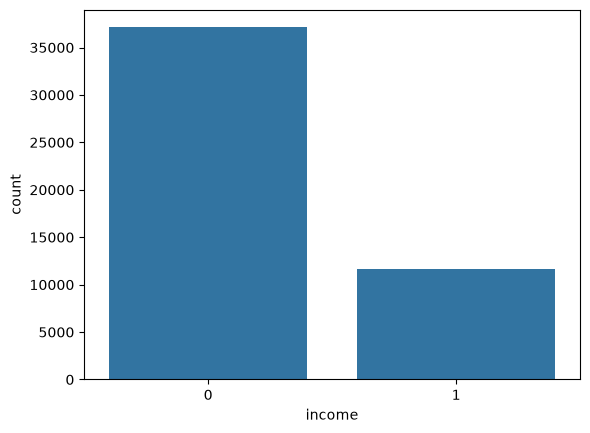

In [25]:
sns.countplot(x=df['income'])
print('Class imbalance is present!')

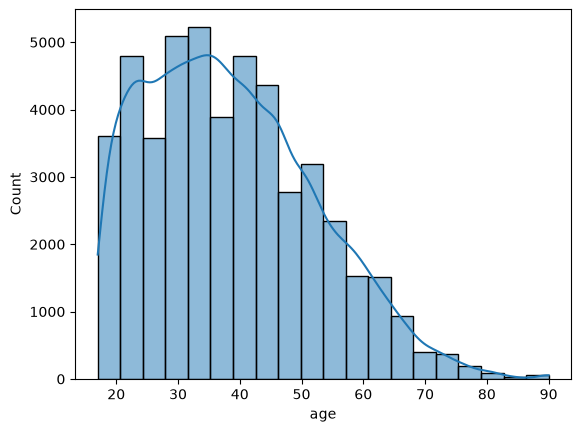

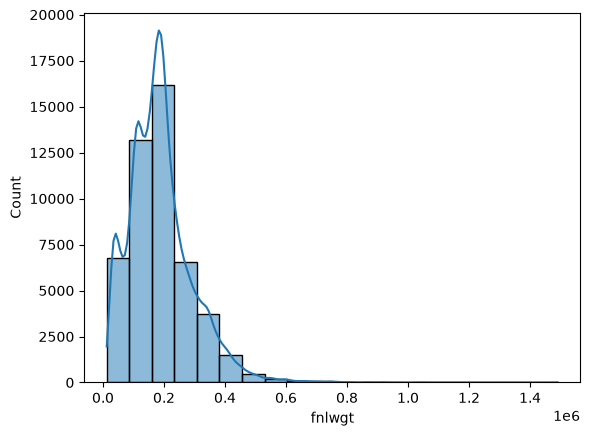

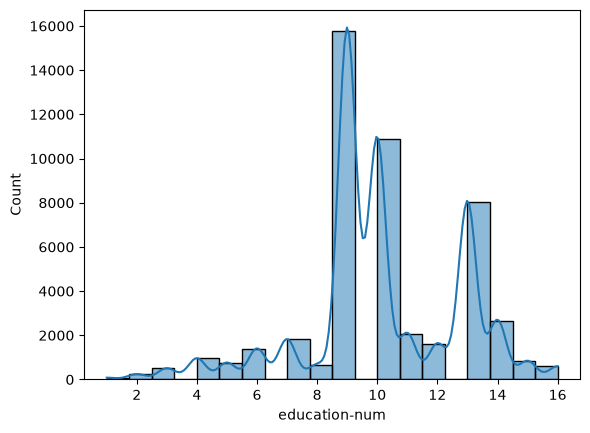

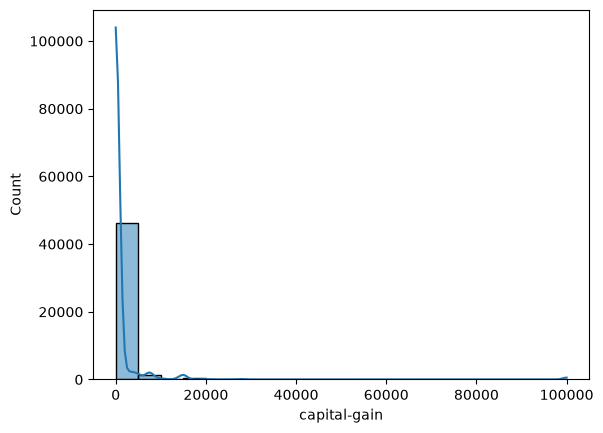

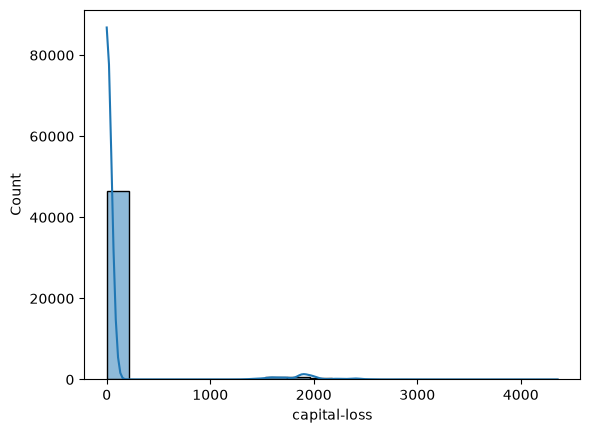

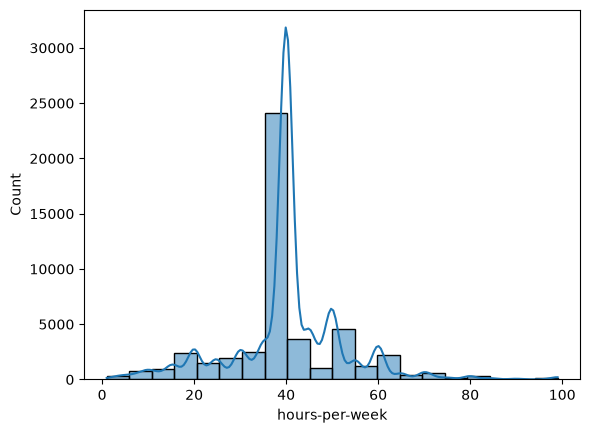

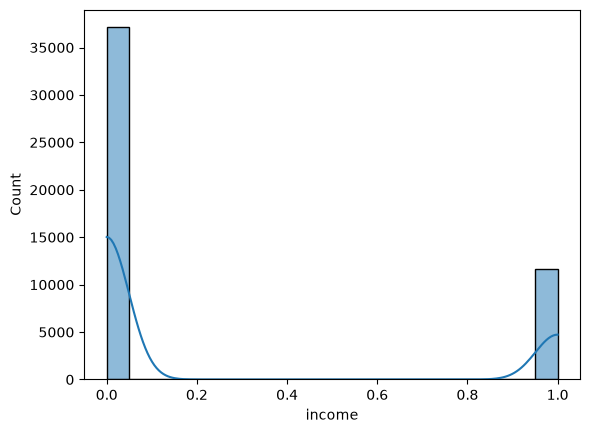

In [26]:
for col in num_col:
    sns.histplot(x=df[col], kde=True, bins=20)
    plt.show()

Relation with target column


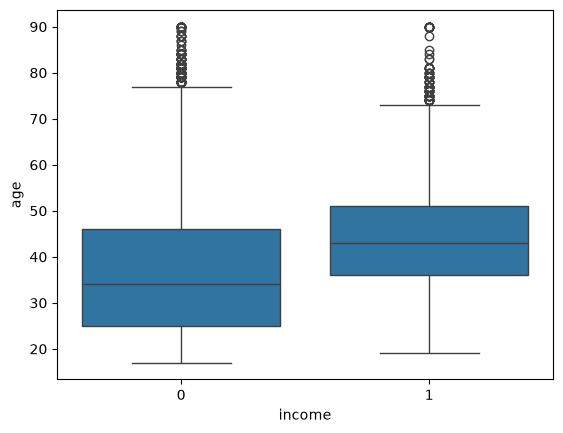

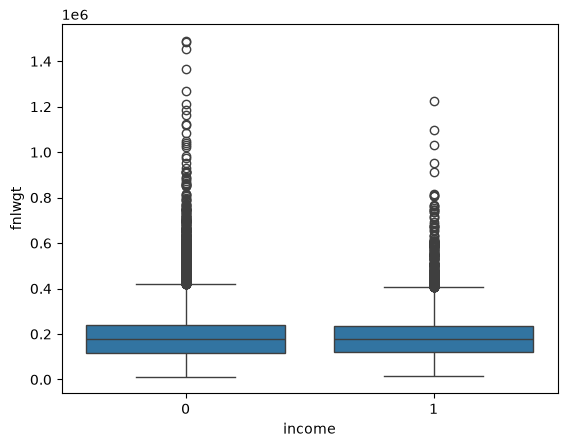

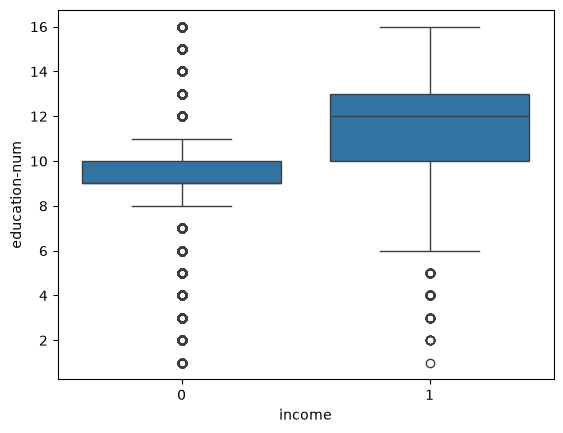

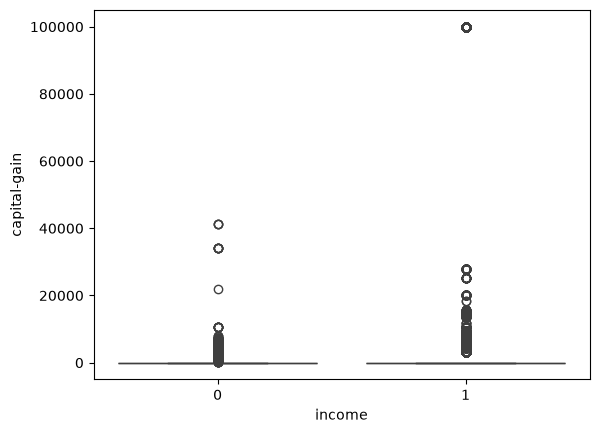

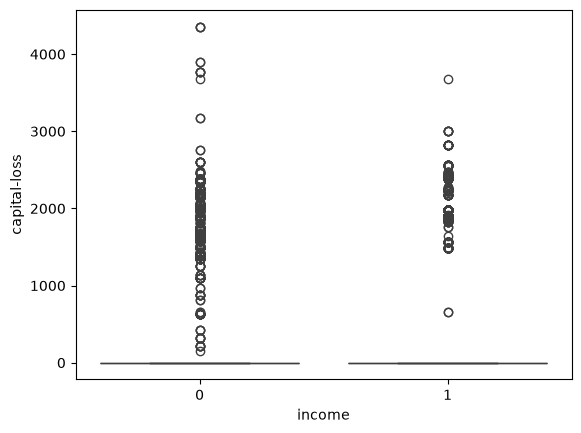

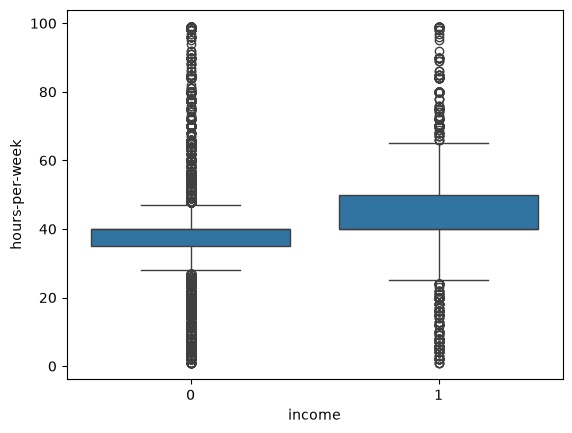

In [27]:

print('Relation with target column')

num_features = df.select_dtypes(include='number').columns.drop('income', errors='ignore')

for col in num_features:
    sns.boxplot(data=df, x='income', y=col)
    plt.show()

In [28]:
#count unique of unique values 
print('Column : unique values')
for col in df:
    print(f'{col} : {df[col].nunique()}')

Column : unique values
age : 74
workclass : 9
fnlwgt : 28523
education : 16
education-num : 16
marital-status : 7
occupation : 15
relationship : 6
race : 5
sex : 2
capital-gain : 123
capital-loss : 99
hours-per-week : 96
native-country : 42
income : 2


## Fixing the skewness

In [ ]:
# Random Forest is a tree model: it splits on thresholds, so it is unaffected by log/scale transforms.
# (Transforming adds a step you must repeat at prediction time, with zero accuracy benefit here.)

for col in ['capital-gain', 'capital-loss']:
    print(f"{col}: skew before = {df[col].skew():.2f} | after log1p = {np.log1p(df[col]).skew():.2f}")

capital-gain: skew before = 11.89 | after log1p = 3.11
capital-loss: skew before = 4.57 | after log1p = 4.30


## Dropping some columns 

In [30]:
# 🔧 CHANGE #4 (BIGGEST ACCURACY FIX):'marital-status' and 'relationship' are among the STRONGEST
# predictors of income in this dataset (married people with a spouse earn >50K far more often).

df = df.drop(columns=['fnlwgt', 'education'])
df.head()

,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [31]:
cat_col = df.select_dtypes(include='object').columns.tolist()
num_col = df.select_dtypes(include=['int64', 'float64']).columns.drop('income',errors='ignore').tolist()
print(cat_col)
print(num_col)

['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']


In [32]:
print('Column : unique values for categorical column')
for col in cat_col:
    print(f'{col} : {df[col].nunique()}')

Column : unique values for categorical column
workclass : 9
marital-status : 7
occupation : 15
relationship : 6
race : 5
sex : 2
native-country : 42


In [33]:
print('Column : unique values for numerical column')
for col in num_col:
    print(f'{col} : {df[col].nunique()}')

Column : unique values for numerical column
age : 74
education-num : 16
capital-gain : 123
capital-loss : 99
hours-per-week : 96


## Correlational Heatmap

<Axes: >

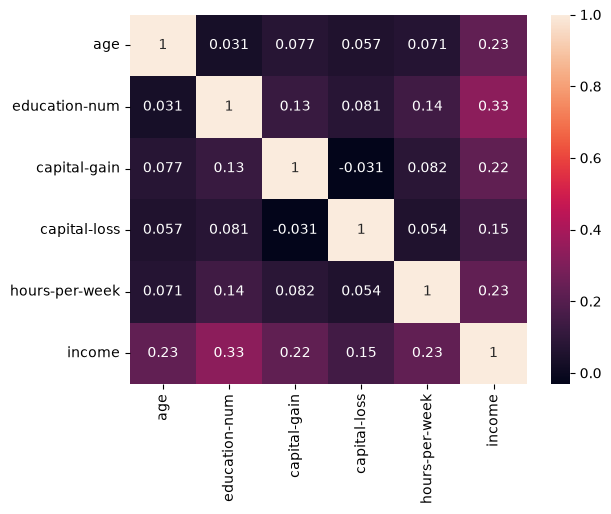

In [34]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## Train Test Split

In [36]:
from sklearn.model_selection import train_test_split

X = df.drop('income', axis=1)
y = df['income']

# 🔧 CHANGE #5: added stratify=y so train and test keep the same ~76/24 class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(39032, 12)
(9758, 12)
(39032,)
(9758,)


## Baseline check

In [37]:
# 🔧 CHANGE #6: always compare against a dumb baseline.
# With ~76% of people in '<=50K', a model that ALWAYS says '<=50K' already gets ~76% accuracy.
# So 79% accuracy (your old result) is barely better than guessing!
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Baseline (always predict <=50K) accuracy : {accuracy_score(y_test, dummy.predict(X_test)):.4f}')

Baseline (always predict <=50K) accuracy : 0.7606


## Creating pipelines  

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(handle_unknown='ignore'), cat_col,),
    ('num', 'passthrough', num_col) 
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [39]:
from sklearn.ensemble import RandomForestClassifier

model = Pipeline([
    ('prep' , preprocessor),
    ('model', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1))
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','workclass','education-num',...,'capital-loss','hours-per-week', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthroug

In [40]:
y_pred = model.predict(X_test)
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_pred
})

compare.head(10)

,Actual,Predicted
30304,0,0
26731,0,0
18008,0,0
20171,0,0
10479,1,1
24061,0,1
39331,0,0
23168,0,0
29537,0,0
15624,0,0


## Evaluating the model accuracy 

In [41]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 🔧 CHANGE #8: accuracy alone is misleading on imbalanced data, so we also track F1 and ROC-AUC
for name, Xs, ys in [('Training', X_train, y_train), ('Testing', X_test, y_test)]:
    pred = model.predict(Xs)
    proba = model.predict_proba(Xs)[:, 1]
    print(f'{name:9s} | accuracy: {accuracy_score(ys, pred):.4f} | F1: {f1_score(ys, pred):.4f} | ROC-AUC: {roc_auc_score(ys, proba):.4f}')

Training  | accuracy: 0.9620 | F1: 0.9259 | ROC-AUC: 0.9975
Testing   | accuracy: 0.8349 | F1: 0.6847 | ROC-AUC: 0.8967


## HyperParameters Tuning 

In [42]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

rf_params = {
    'model__n_estimators'      : [100, 200, 300, 500],
    'model__max_depth'         : [10, 15, 20, 30, None],
    'model__min_samples_leaf'  : [1, 2, 3, 5],
    'model__min_samples_split' : [2, 5, 10],
    'model__max_features'      : ['sqrt', 'log2', 0.5],
}

# 🔧 CHANGE #10: StratifiedKFold keeps the class ratio in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_search = RandomizedSearchCV(
    param_distributions=rf_params,
    cv = cv,
    estimator=model,
    n_iter=15,
    # Use a classification metric.
    # F1 is a good choice for imbalanced data ('roc_auc' is another good one).
    scoring='f1',
    random_state=42,
    n_jobs=-1,
)

rf_search.fit(X_train,y_train)
print(f'Best cross-validated F1 : {rf_search.best_score_:.4f}')

Best cross-validated F1 : 0.7016


In [43]:
print(f'Training Accuracy : {rf_search.score(X_train,y_train)}')
print(f'Testing Accuracy : {rf_search.score(X_test,y_test)}')

Training Accuracy : 0.8007626310772163
Testing Accuracy : 0.6988388969521045


## Best Parameters found for this Dataset

In [44]:
rf_search.best_params_

{'model__n_estimators': 300,
 'model__min_samples_split': 10,
 'model__min_samples_leaf': 3,
 'model__max_features': 0.5,
 'model__max_depth': None}

In [45]:
y_pred2 = rf_search.predict(X_test)
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_pred2
})

compare.head(10)

,Actual,Predicted
30304,0,0
26731,0,0
18008,0,0
20171,0,0
10479,1,1
24061,0,0
39331,0,0
23168,0,0
29537,0,0
15624,0,0


## Scores after parameter tuning 

In [ ]:
for name, Xs, ys in [('Training', X_train, y_train), ('Testing', X_test, y_test)]:
    pred = rf_search.predict(Xs)
    proba = rf_search.predict_proba(Xs)[:, 1]
    print(f'{name:9s} | accuracy: {accuracy_score(ys, pred):.4f} | F1: {f1_score(ys, pred):.4f} | ROC-AUC: {roc_auc_score(ys, proba):.4f}')

Training  | accuracy: 0.8876 | F1: 0.8008 | ROC-AUC: 0.9716
Testing   | accuracy: 0.8299 | F1: 0.6988 | ROC-AUC: 0.9193


=== Tuned model: classification report (test set) ===
              precision    recall  f1-score   support

       <=50K       0.94      0.83      0.88      7422
        >50K       0.61      0.82      0.70      2336

    accuracy                           0.83      9758
   macro avg       0.77      0.83      0.79      9758
weighted avg       0.86      0.83      0.84      9758



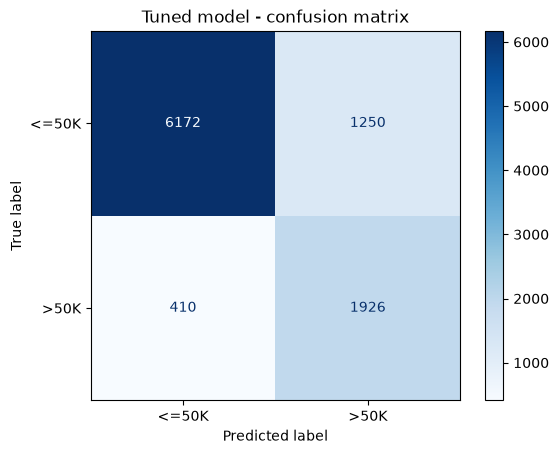

,Baseline (always <=50K),Untuned RF,Tuned RF
Accuracy,0.7606,0.8349,0.8299
F1 (>50K),0.0000,0.6847,0.6988
ROC-AUC,0.5000,0.8967,0.9193


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print(classification_report(y_test, y_pred2, target_names=['<=50K', '>50K']))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred2, display_labels=['<=50K', '>50K'], cmap='Blues')
plt.title('Tuned model - confusion matrix')
plt.show()

# Side-by-side comparison of untuned vs tuned
results = pd.DataFrame({
    'Baseline (always <=50K)': [accuracy_score(y_test, dummy.predict(X_test)), f1_score(y_test, dummy.predict(X_test)), 0.5],
    'Untuned RF': [accuracy_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])],
    'Tuned RF'  : [accuracy_score(y_test, y_pred2), f1_score(y_test, y_pred2), roc_auc_score(y_test, rf_search.predict_proba(X_test)[:, 1])],
}, index=['Accuracy', 'F1 (>50K)', 'ROC-AUC']).round(4)
results

## Feature importance

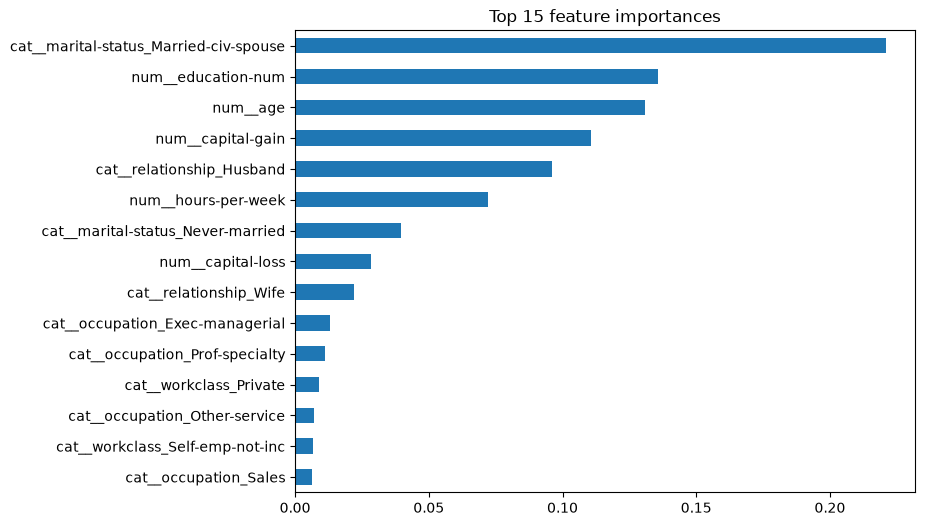

In [ ]:
best_pipe = rf_search.best_estimator_
feature_names = best_pipe.named_steps['prep'].get_feature_names_out()
importances = pd.Series(best_pipe.named_steps['model'].feature_importances_, index=feature_names)

importances.sort_values(ascending=False).head(15).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 feature importances')
plt.show()

## Saving the model

In [49]:
import joblib
joblib.dump(rf_search.best_estimator_, 'model.pkl')
print('Model saved to model.pkl')

Model saved to model.pkl
